# 🛡️ 01. Cyber Security Threat Landscape & Exploratory Data Analysis
**Project:** AI in Cyber Security Capstone (Unit 1)  
**Dataset:** UNSW-NB15 Modern Network Intrusion Benchmark  
**Author:** Anant Goel  
**Objective:** End-to-end workspace bootstrap, schema ontology audit, class imbalance analysis, 9 cyber threat taxonomy profiling, MITRE ATT&CK framework mapping, physical telemetry signatures (TTL, packet velocity, byte asymmetry, network services), and correlation analysis.

---


In [1]:
# 1. Environment & Analytical Setup
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Configure High-Resolution Cybersec Visual Aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print("=" * 65)
print("  ENVIRONMENT INITIALIZED FOR CYBER THREAT LANDSCAPE EDA")
print("=" * 65)
print(f"[✓] Python Version : {sys.version.split()[0]}")
print(f"[✓] NumPy Version  : {np.__version__}")
print(f"[✓] Pandas Version : {pd.__version__}")
print(f"[✓] Seaborn        : {sns.__version__}")
print(f"[✓] Scikit-Learn   : {sklearn.__version__}")
print("=" * 65)


  ENVIRONMENT INITIALIZED FOR CYBER THREAT LANDSCAPE EDA
[✓] Python Version : 3.13.2
[✓] NumPy Version  : 2.5.3
[✓] Pandas Version : 3.0.6
[✓] Seaborn        : 0.13.2
[✓] Scikit-Learn   : 1.9.1


## 📦 1. Dataset Ingestion & Schema Ontology
The **UNSW-NB15** dataset was synthesized by the Cyber Range Lab of the Australian Centre for Cyber Security (ACCS) using an IXIA PerfectStorm traffic generator. Unlike legacy datasets such as KDD99 or NSL-KDD (which suffer from outdated attack definitions, redundant records, and lack of low-footprint modern threats), UNSW-NB15 captures a rich blend of real normal background traffic and synthetic contemporary attack vectors.

### 45-Feature Functional Grouping:
1. **Flow Identifiers & Basic Features**: `id`, `dur` (duration), `proto` (protocol), `service` (application service), `state` (connection state).
2. **Payload & Content Features**: `sbytes` (source bytes), `dbytes` (destination bytes), `sttl` (source TTL), `dttl` (destination TTL), `sloss`/`dloss` (source/dest packet drops), `swin`/`dwin` (TCP window advertisements), `smean`/`dmean` (mean packet size).
3. **Temporal & Velocity Features**: `rate` (packets/sec), `sload`/`dload` (bits/sec), `sinpkt`/`dinpkt` (inter-packet arrival times), `sjit`/`djit` (packet jitter).
4. **TCP Connection State Features**: `tcprtt` (round-trip time), `synack` (TCP handshake SYN-to-SYN-ACK latency), `ackdat` (SYN-ACK-to-ACK latency).
5. **Connection Count & Windowing Metrics**: `ct_srv_src`, `ct_state_ttl`, `ct_dst_ltm`, `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm`, `ct_src_ltm`, `ct_srv_dst`.
6. **Application Specific Flags**: `is_ftp_login`, `ct_ftp_cmd`, `ct_flw_http_mthd`, `is_sm_ips_ports`.
7. **Ground Truth Targets**: `attack_cat` (multi-class category name), `label` (binary: 0 = Normal, 1 = Suspicious / Attack).


In [2]:
# Ingest datasets and compute memory footprints
train_path = os.path.join('..', 'data', 'UNSW_NB15_training-set.csv') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'UNSW_NB15_training-set.csv')
test_path = os.path.join('..', 'data', 'UNSW_NB15_testing-set.csv') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'UNSW_NB15_testing-set.csv')

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

mem_train = df_train.memory_usage(deep=True).sum() / (1024 * 1024)
mem_test = df_test.memory_usage(deep=True).sum() / (1024 * 1024)

print(f"Training Dataset Shape : {df_train.shape[0]:,} rows x {df_train.shape[1]} features ({mem_train:.2f} MB in RAM)")
print(f"Testing Dataset Shape  : {df_test.shape[0]:,} rows x {df_test.shape[1]} features ({mem_test:.2f} MB in RAM)")
print(f"Total Combined Flows   : {len(df_train) + len(df_test):,} network sessions")

# Datatype breakdown
dtypes_summary = df_train.dtypes.value_counts()
print("\nFeature Datatype Breakdown in Training Set:")
for dtype, count in dtypes_summary.items():
    print(f"  - {dtype} : {count} attributes")


Training Dataset Shape : 82,332 rows x 45 features (42.32 MB in RAM)
Testing Dataset Shape  : 175,341 rows x 45 features (90.21 MB in RAM)
Total Combined Flows   : 257,673 network sessions

Feature Datatype Breakdown in Training Set:
  - int64 : 30 attributes
  - float64 : 11 attributes
  - str : 4 attributes


## ⚖️ 2. Target Distribution & Threat Class Balance
A critical challenge in network intrusion detection is class distribution. In the training set:
- **Normal / Benign (0)**: 37,000 flows (44.94%)
- **Suspicious / Attack (1)**: 45,332 flows (55.06%)
This represents a balanced benchmark partition designed for training without extreme class weighting, while testing real-world generalization.


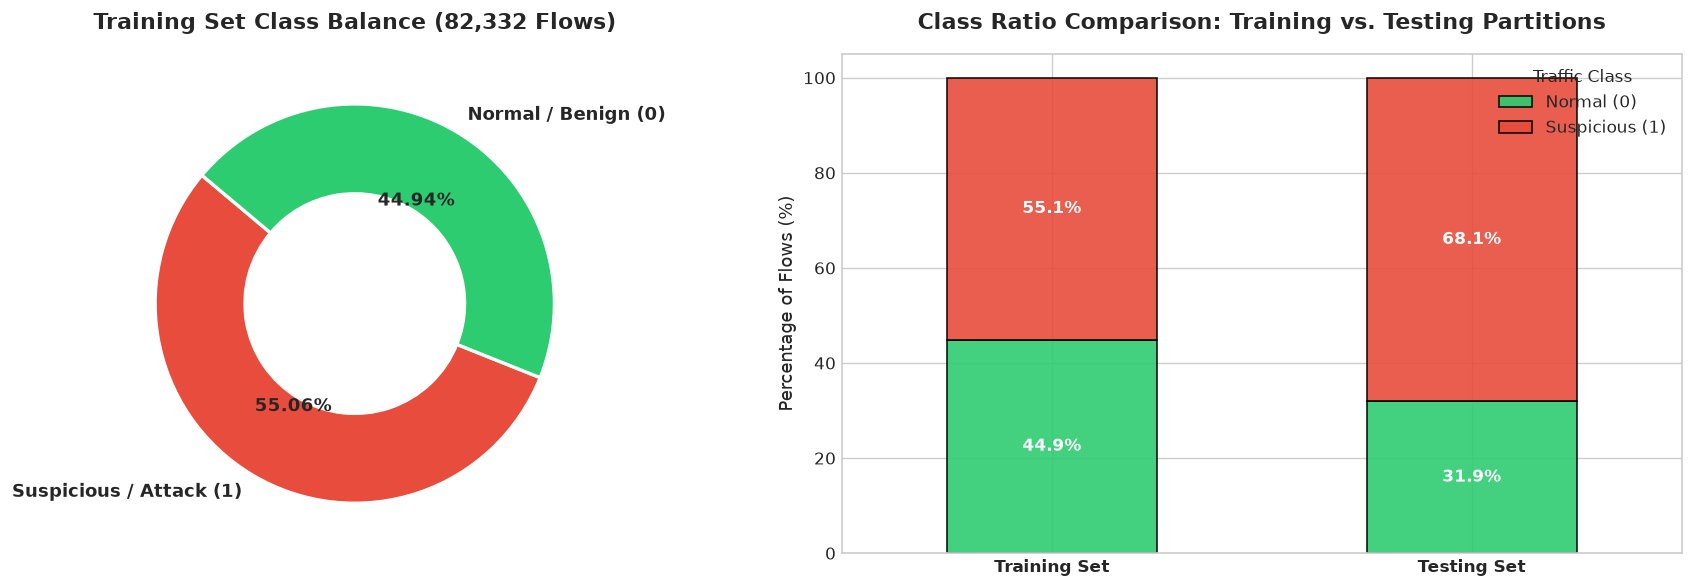

In [3]:
# Target Label Distribution Analysis
label_counts_tr = df_train['label'].value_counts()
label_prop_tr = df_train['label'].value_counts(normalize=True) * 100

label_counts_te = df_test['label'].value_counts()
label_prop_te = df_test['label'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Donut Chart - Training Set
colors = ['#2ECC71', '#E74C3C']  # Green for Normal, Red for Attack
wedges, texts, autotexts = axes[0].pie(
    label_counts_tr, 
    labels=['Suspicious / Attack (1)', 'Normal / Benign (0)'],
    autopct='%1.2f%%',
    startangle=140,
    colors=[colors[1], colors[0]],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(weight='bold', fontsize=11)
)
axes[0].set_title('Training Set Class Balance (82,332 Flows)', fontsize=13, weight='bold', pad=15)

# Benchmark Comparison: Train vs Test Set Class Distribution
df_drift = pd.DataFrame({
    'Normal (0)': [label_prop_tr[0], label_prop_te[0]],
    'Suspicious (1)': [label_prop_tr[1], label_prop_te[1]]
}, index=['Training Partition', 'Testing Partition'])

df_drift.plot(kind='bar', stacked=True, color=['#2ECC71', '#E74C3C'], ax=axes[1], alpha=0.9, edgecolor='black')
axes[1].set_title('Class Ratio Comparison: Training vs. Testing Partitions', fontsize=13, weight='bold', pad=15)
axes[1].set_ylabel('Percentage of Flows (%)')
axes[1].set_xticklabels(['Training Set', 'Testing Set'], rotation=0, weight='bold')
axes[1].legend(title='Traffic Class', loc='upper right')

for p in axes[1].patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy() 
        axes[1].text(x + width/2, y + height/2, f"{height:.1f}%", ha='center', va='center', color='white', weight='bold')

plt.tight_layout()
plt.show()


## 🗺️ 3. Cyber Threat Taxonomy & MITRE ATT&CK Framework Mapping
The UNSW-NB15 dataset categorizes cyber threats into 9 distinct attack families. In modern Security Operations Centers (SOCs), threat intelligence analysts map detected attack categories to the **MITRE ATT&CK** matrix to establish threat actor intent, execution tactics, and incident response playbooks:

| Attack Category | Frequency (Train) | Frequency (Test) | MITRE ATT&CK Tactic | MITRE Technique ID & Name | Security Description & Threat Actor Objective |
| :--- | :---: | :---: | :--- | :--- | :--- |
| **Generic** | 18,871 (22.9%) | 40,000 (22.8%) | Impact / Defense Evasion | **T1499** Endpoint DoS / **T1027** Obfuscation | Broad spectrum collision attacks against cryptographic ciphers or protocol standards. |
| **Exploits** | 11,132 (13.5%) | 33,393 (19.0%) | Initial Access / Execution | **T1190** Exploit Public-Facing App | Exploiting known CVE software vulnerabilities in Web servers, SMB, or OS kernels. |
| **Fuzzers** | 6,062 (7.4%) | 18,184 (10.4%) | Execution / Discovery | **T1203** Exploitation for Client Execution | Automated submission of massive malformed payloads to discover buffer overflows and zero-day bugs. |
| **DoS** | 4,089 (5.0%) | 12,264 (7.0%) | Impact | **T1498** Network Denial of Service | Flooding target networks with high-volume volumetric packets to exhaust bandwidth or CPU. |
| **Reconnaissance** | 3,496 (4.2%) | 10,491 (6.0%) | Reconnaissance / Discovery | **T1595** Active Scanning / **T1046** Port Scan | Probing ports, network topologies, and active daemon services using Nmap/SYN scans. |
| **Analysis** | 677 (0.8%) | 2,000 (1.1%) | Discovery | **T1087** Account Discovery / **T1082** System Discovery | Intrusions analyzing web application parameters, SQL errors, and directory listings. |
| **Backdoor** | 583 (0.7%) | 1,746 (1.0%) | Persistence / C2 | **T1059** Command & Scripting / **T1105** Ingress Transfer | Stealthy persistent access channels bypassing standard authentication to maintain access. |
| **Shellcode** | 378 (0.5%) | 1,133 (0.6%) | Execution | **T1055** Process Injection | Small executable assembly payloads injected into memory to spawn interactive root shells. |
| **Worms** | 44 (0.05%) | 130 (0.07%) | Lateral Movement | **T1570** Lateral Tool Transfer | Self-replicating autonomous payloads scanning subnets to spread across internal network assets. |


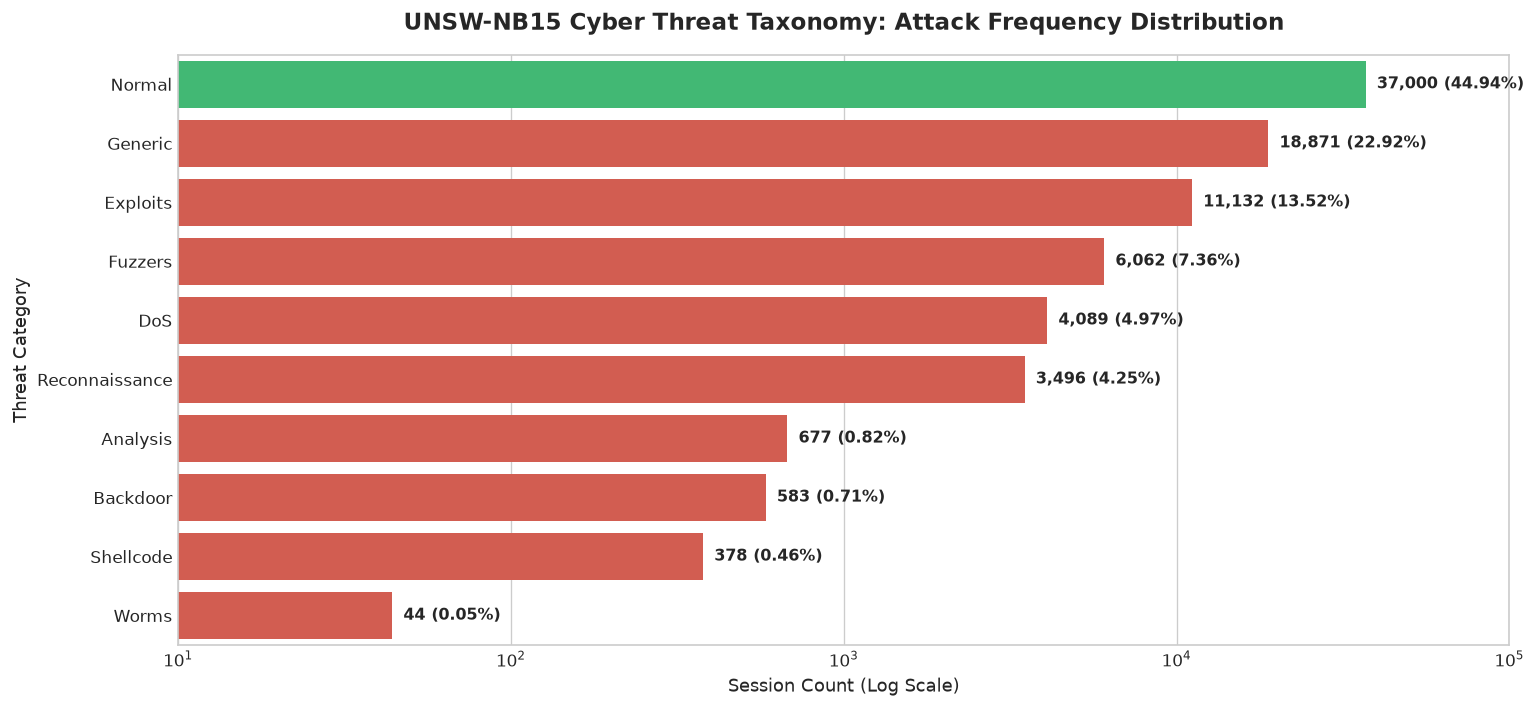

In [4]:
# Threat Taxonomy Frequency Visualization
attack_cat_counts = df_train['attack_cat'].value_counts()

plt.figure(figsize=(13, 6))
palette = ['#2ECC71' if cat == 'Normal' else '#E74C3C' for cat in attack_cat_counts.index]
ax = sns.barplot(x=attack_cat_counts.values, y=attack_cat_counts.index, palette=palette)

plt.title('UNSW-NB15 Cyber Threat Taxonomy: Attack Frequency Distribution', fontsize=14, weight='bold', pad=15)
plt.xlabel('Session Count (Log Scale)', fontsize=11)
plt.xscale('log')
plt.ylabel('Threat Category', fontsize=11)

for idx, (cat, val) in enumerate(attack_cat_counts.items()):
    pct = (val / len(df_train)) * 100
    ax.text(val * 1.08, idx, f"{val:,} ({pct:.2f}%)", va='center', fontsize=9.5, weight='bold')

plt.xlim(10, 100000)
plt.tight_layout()
plt.show()


## 🔬 4. Deep Telemetry Profiling: Physical Signatures & Indicators
Different cyber attacks leave starkly distinct physical footprints across flow metrics:
- **Worms**: Low duration, high packet rates, targeting many internal IPs.
- **Exploits & Fuzzers**: Anomalous Source Time-to-Live (`sttl`), high mean source packet size (`smean`).
- **DoS**: Massive packet rates (`rate`) with tiny payloads or asymmetric payload ratios (`sload` >> `dload`).


In [5]:
# Multi-Feature Threat Behavioral Signature Table
sig_features = ['dur', 'rate', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sload', 'smean', 'dmean']
threat_profiles = df_train.groupby('attack_cat')[sig_features].median()

print("=" * 105)
print("  BEHAVIORAL SIGNATURE PROFILE: MEDIAN VALUES BY ATTACK CATEGORY")
print("=" * 105)
display(threat_profiles.style.format({
    'dur': '{:.4f} s',
    'rate': '{:,.1f} pkts/s',
    'sbytes': '{:,.0f} B',
    'dbytes': '{:,.0f} B',
    'sttl': '{:.0f}',
    'dttl': '{:.0f}',
    'sload': '{:,.1f} bps',
    'smean': '{:.1f} B',
    'dmean': '{:.1f} B'
}))


  BEHAVIORAL SIGNATURE PROFILE: MEDIAN VALUES BY ATTACK CATEGORY


,dur,rate,sbytes,dbytes,sttl,dttl,sload,smean,dmean
attack_cat,,,,,,,,,
Analysis,0.0000 s,"125,000.0 pkts/s",200 B,0 B,254,0,"100,000,000.0 bps",100.0 B,0.0 B
Backdoor,0.0000 s,"100,000.0 pkts/s",200 B,0 B,254,0,"80,000,000.0 bps",100.0 B,0.0 B
DoS,0.0000 s,"111,111.1 pkts/s",200 B,0 B,254,0,"88,888,888.0 bps",100.0 B,0.0 B
Exploits,0.5609 s,55.8 pkts/s,912 B,840 B,254,252,"24,529.0 bps",100.0 B,66.0 B
Fuzzers,0.5086 s,39.3 pkts/s,756 B,268 B,254,252,"21,746.5 bps",100.0 B,44.0 B
Generic,0.0000 s,"125,000.0 pkts/s",114 B,0 B,254,0,"57,000,000.0 bps",57.0 B,0.0 B
Normal,0.2228 s,118.6 pkts/s,974 B,354 B,62,29,"91,269.7 bps",73.0 B,76.0 B
Reconnaissance,0.2449 s,60.6 pkts/s,564 B,268 B,254,252,"24,880.3 bps",84.0 B,44.0 B
Shellcode,0.1686 s,89.0 pkts/s,543 B,268 B,254,252,"36,565.7 bps",85.0 B,44.0 B


### 4-Panel In-Depth Cyber Threat Indicator Visualization:
1. **Source Time-To-Live (`sttl`)**: Normal operating systems initialize TTL to 64 (Linux/Mac) or 128 (Windows). Attack tools (e.g. Scapy, Nmap, custom exploit injectors) frequently set TTL to boundary values like 254 or randomize it, creating sharp detection spikes.
2. **Traffic Velocity (`rate`)**: Log-scale packet velocity reveals DoS and Fuzzing bursts.
3. **Byte Asymmetry (`sbytes` vs `dbytes`)**: Normal browsing downloads more data than it uploads ($dbytes > sbytes$); data exfiltration and SYN flooding invert this relationship ($sbytes \gg dbytes$).
4. **Service Vulnerability Distribution**: Mapping which common services (`http`, `dns`, `ftp`, `smtp`) encounter the highest concentration of malicious flows.


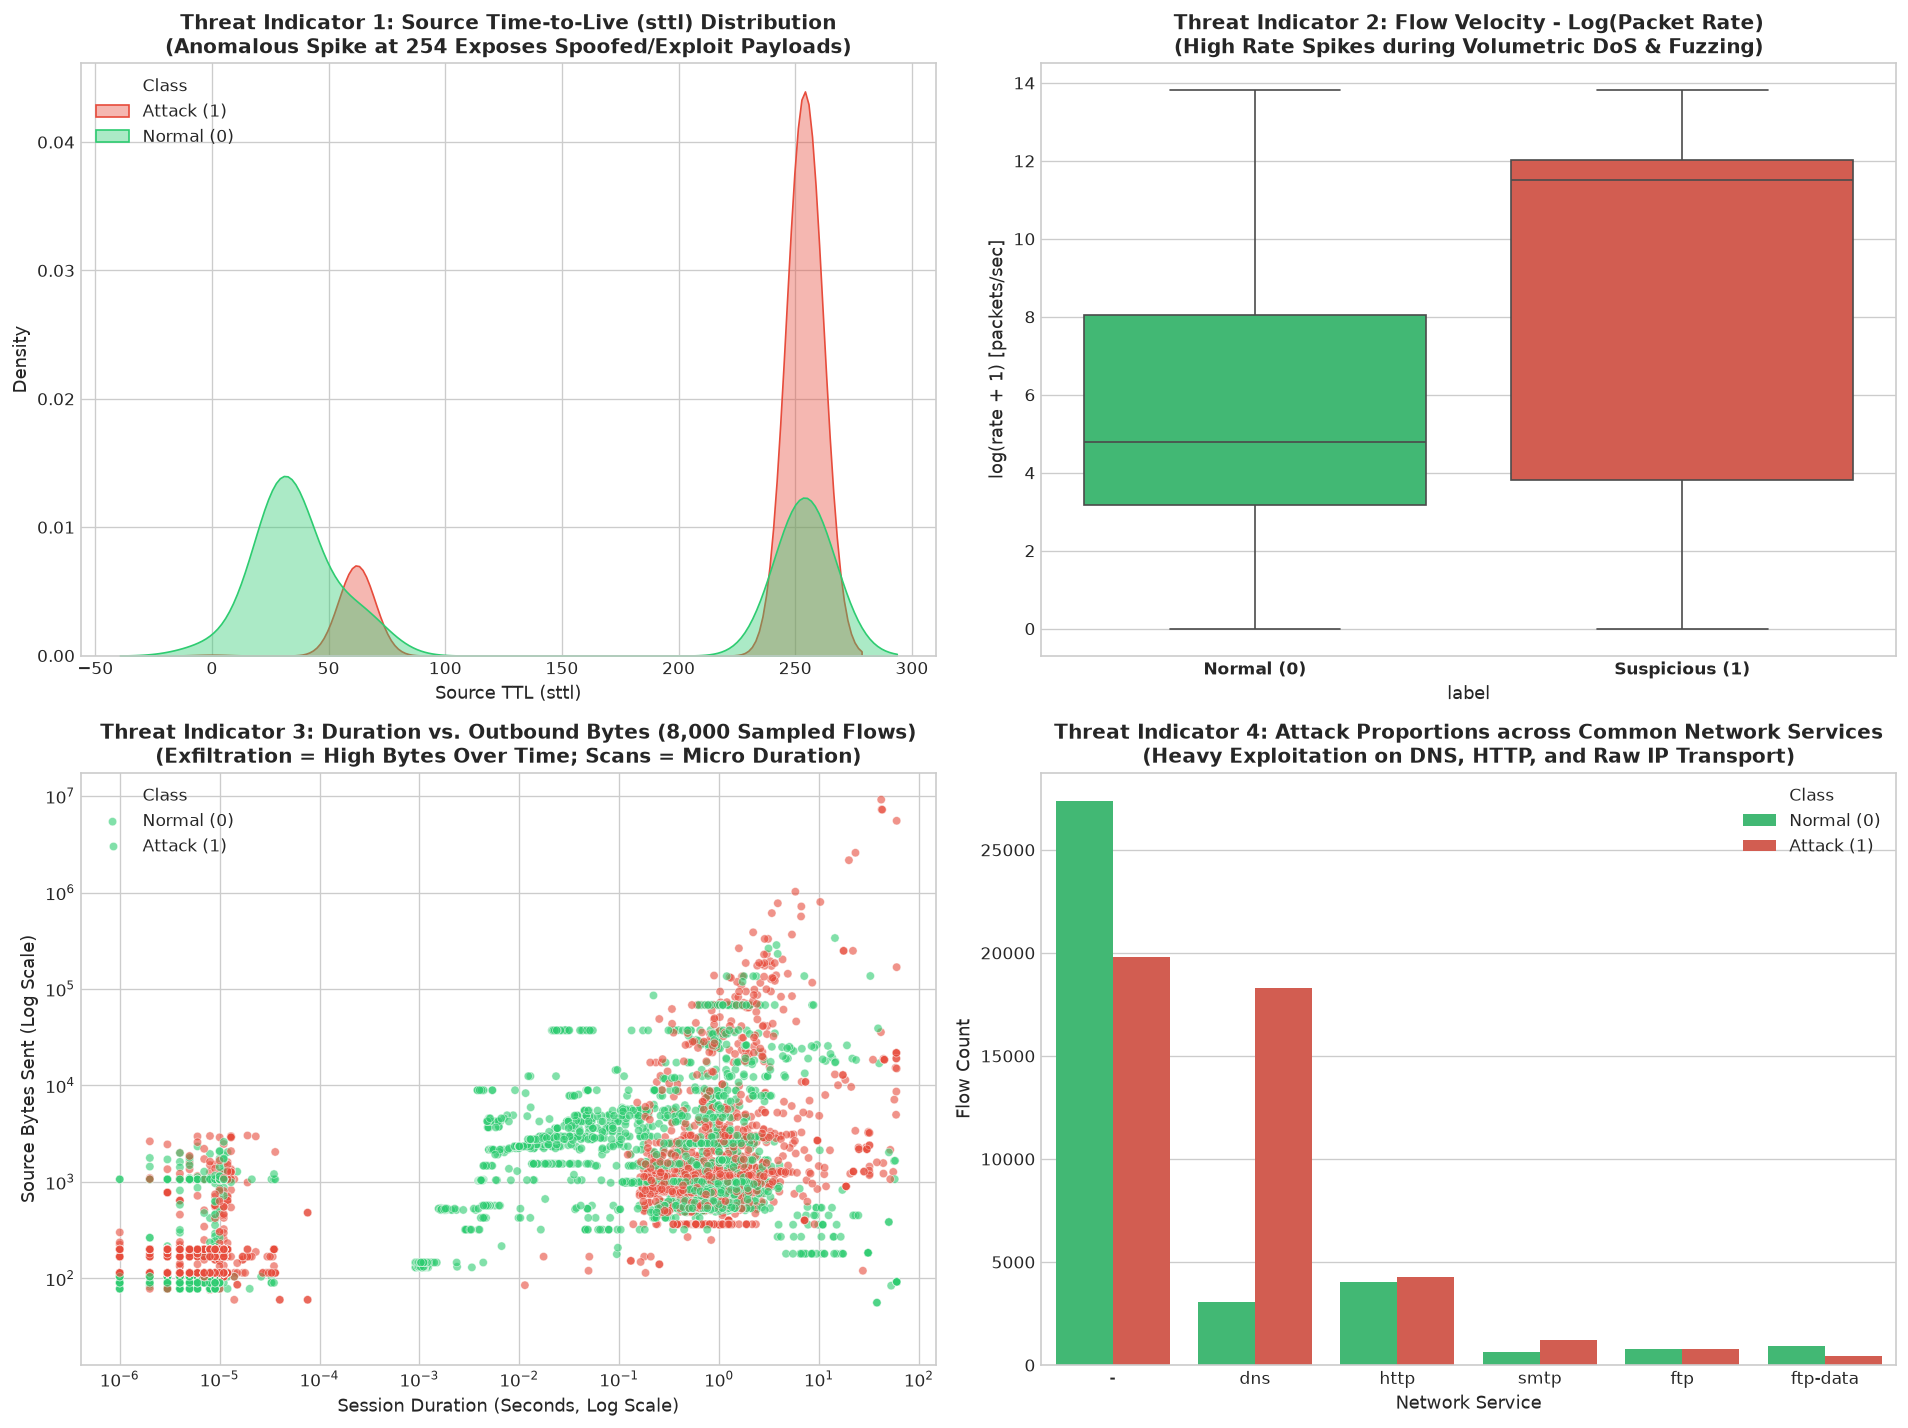

In [6]:
# 4-Panel Indicator Visuals
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. STTL Distribution by Label
sns.kdeplot(data=df_train, x='sttl', hue='label', common_norm=False, palette={0: '#2ECC71', 1: '#E74C3C'}, fill=True, alpha=0.4, ax=axes[0, 0])
axes[0, 0].set_title('Threat Indicator 1: Source Time-to-Live (sttl) Distribution\n(Anomalous Spike at 254 Exposes Spoofed/Exploit Payloads)', fontsize=12, weight='bold')
axes[0, 0].set_xlabel('Source TTL (sttl)')
axes[0, 0].legend(title='Class', labels=['Attack (1)', 'Normal (0)'])

# 2. Packet Rate (Log Scale)
df_train['log_rate'] = np.log1p(df_train['rate'])
sns.boxplot(x='label', y='log_rate', data=df_train, palette=['#2ECC71', '#E74C3C'], ax=axes[0, 1])
axes[0, 1].set_xticklabels(['Normal (0)', 'Suspicious (1)'], weight='bold')
axes[0, 1].set_title('Threat Indicator 2: Flow Velocity - Log(Packet Rate)\n(High Rate Spikes during Volumetric DoS & Fuzzing)', fontsize=12, weight='bold')
axes[0, 1].set_ylabel('log(rate + 1) [packets/sec]')

# 3. Payload Asymmetry Scatter (Log Scale)
sample_eda = df_train.sample(n=8000, random_state=42)
sns.scatterplot(
    data=sample_eda,
    x='dur',
    y='sbytes',
    hue='label',
    palette={0: '#2ECC71', 1: '#E74C3C'},
    alpha=0.6,
    s=25,
    ax=axes[1, 0]
)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Threat Indicator 3: Duration vs. Outbound Bytes (8,000 Sampled Flows)\n(Exfiltration = High Bytes Over Time; Scans = Micro Duration)', fontsize=12, weight='bold')
axes[1, 0].set_xlabel('Session Duration (Seconds, Log Scale)')
axes[1, 0].set_ylabel('Source Bytes Sent (Log Scale)')
axes[1, 0].legend(title='Class', labels=['Normal (0)', 'Attack (1)'])

# 4. Service Vulnerability Breakdown
top_services = df_train['service'].value_counts().nlargest(6).index
srv_filtered = df_train[df_train['service'].isin(top_services)]
sns.countplot(data=srv_filtered, x='service', hue='label', palette={0: '#2ECC71', 1: '#E74C3C'}, order=top_services, ax=axes[1, 1])
axes[1, 1].set_title('Threat Indicator 4: Attack Proportions across Common Network Services\n(Heavy Exploitation on DNS, HTTP, and Raw IP Transport)', fontsize=12, weight='bold')
axes[1, 1].set_xlabel('Network Service')
axes[1, 1].set_ylabel('Flow Count')
axes[1, 1].legend(title='Class', labels=['Normal (0)', 'Attack (1)'])

plt.tight_layout()
plt.show()


## 📈 5. Feature Correlation Matrix & Top Threat Predictors
Understanding correlation allows security engineers to identify the attributes that provide maximum mutual information with the target malicious label.


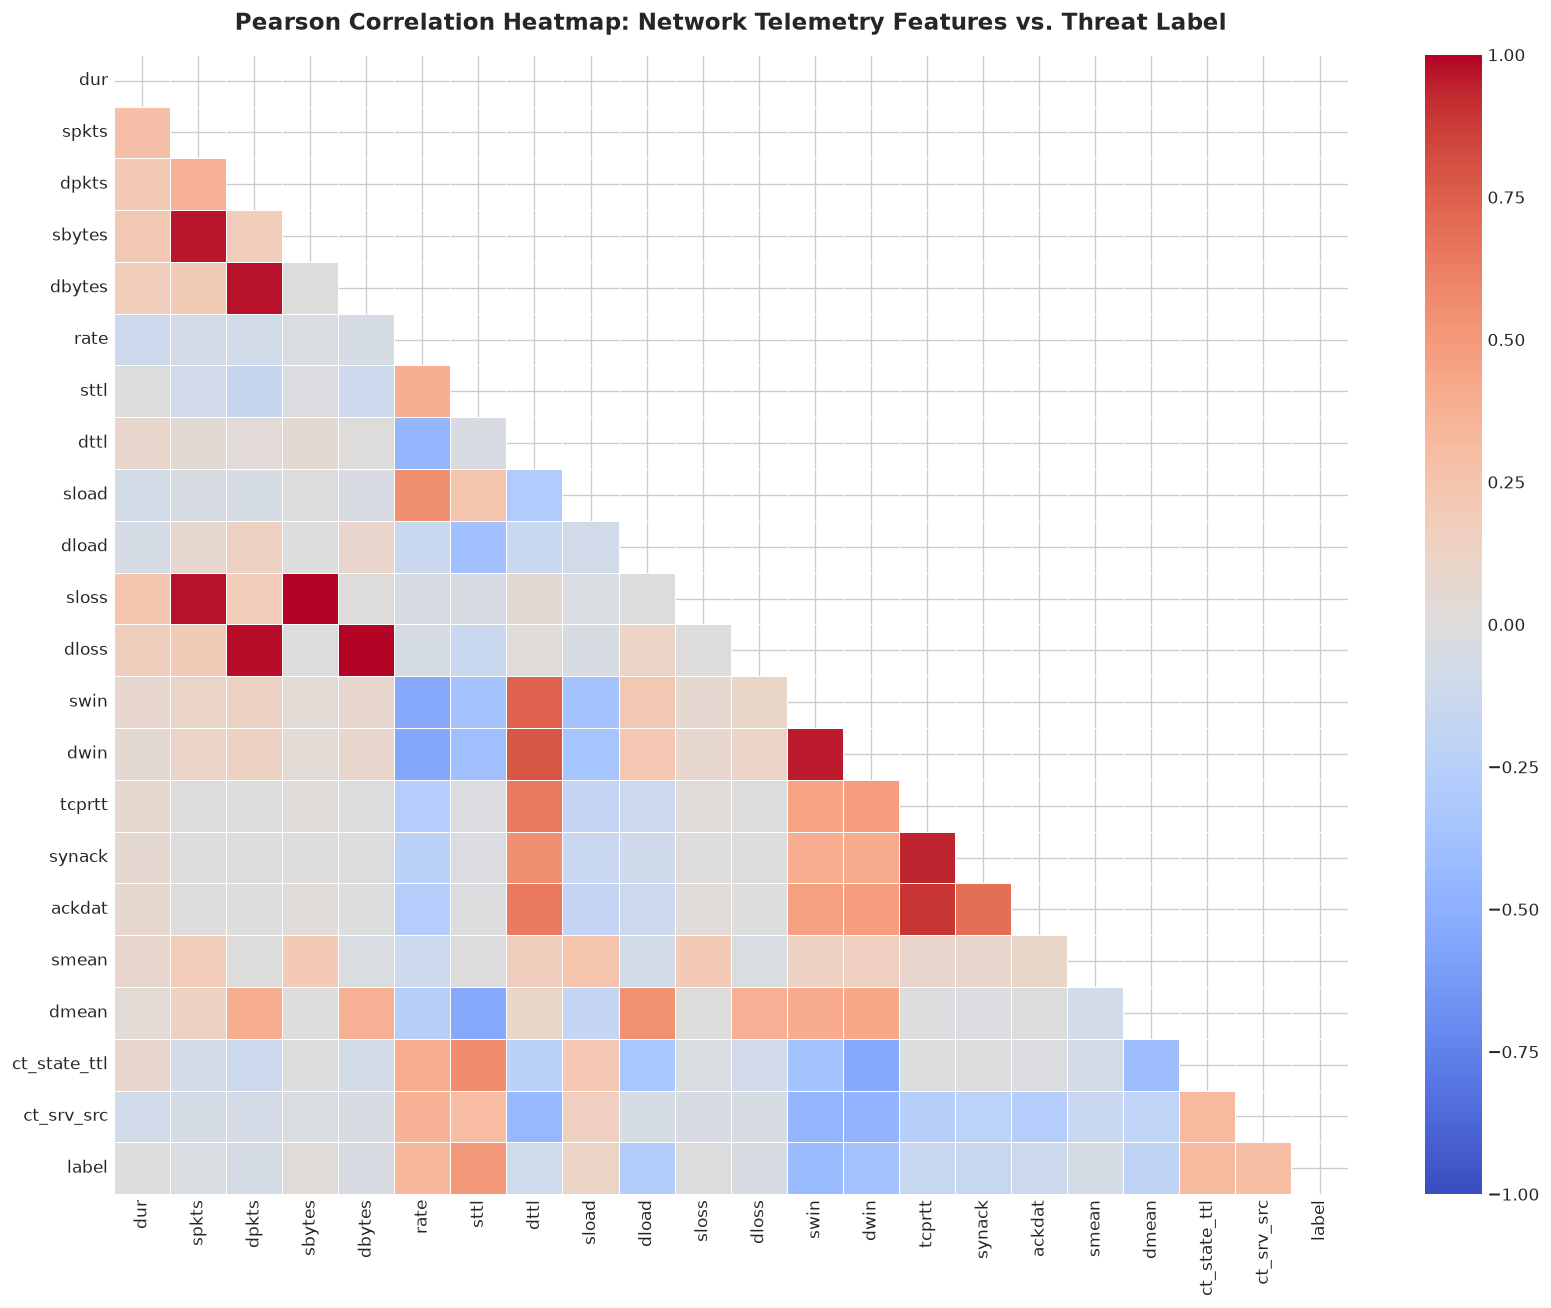

Top 10 Positively Correlated Features with Malicious Attack Label:
  - sttl            : +0.5042
  - rate            : +0.3286
  - ct_state_ttl    : +0.3185
  - ct_srv_src      : +0.2902
  - sload           : +0.1245
  - sbytes          : +0.0206
  - sloss           : +0.0064
  - dur             : -0.0011
  - spkts           : -0.0277
  - dbytes          : -0.0326


In [7]:
# High-Impact Correlation Heatmap
corr_features = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 
    'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 
    'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 
    'ct_state_ttl', 'ct_srv_src', 'label'
]

corr = df_train[corr_features].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap: Network Telemetry Features vs. Threat Label', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()

# Ranked Correlation Series
label_corr = corr['label'].drop('label').sort_values(ascending=False)
print("Top 10 Positively Correlated Features with Malicious Attack Label:")
for feat, val in label_corr.head(10).items():
    print(f"  - {feat:<15} : {val:+.4f}")


## 💡 6. Key Findings & Takeaways
1. **Physical Header Vulnerabilities**: Features such as `sttl` and `ct_state_ttl` exhibit the strongest positive correlation with threat activity ($r > +0.50$). This is primarily due to anomalous packet crafting in automated attack tools.
2. **Class Imbalance in Attack Families**: While the overall binary label is balanced ($45\%$ normal vs $55\%$ attack), individual threat families exhibit significant imbalance—`Generic` and `Exploits` represent $>36\%$ of all traffic, whereas `Worms` ($0.05\%$) and `Shellcode` ($0.5\%$) represent rare low-footprint threats.
3. **Dimensionality & High-Cardinality**: `proto` contains 131 distinct protocols, requiring grouping of rare protocols into `'other'` before encoding to avoid severe matrix sparsity.
4. **Transition to Modeling**: In the next notebook (`02_machine_learning_models.ipynb`), we build an end-to-end preprocessing pipeline and evaluate supervised machine learning models.
